# 01 — Exploratory data analysis of the development panel

Plots only; all logic lives in `src/vn_rank`. Run `vn-rank features` first.

The panel holds signal dates before `lockbox_start` (prices end on 2025-09-30), so no
lockbox data is shown. This notebook looks at features, missingness, and the universe; it
does **not** relate features to forward returns (that is Phase 3, on walk-forward folds).

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PANEL = ROOT / "data" / "processed" / "panel.parquet"
SCHEMA = json.loads((ROOT / "data" / "processed" / "schema.json").read_text(encoding="utf-8"))
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])

panel = pd.read_parquet(PANEL)
groups = SCHEMA["feature_groups"]
features = [name for names in groups.values() for name in names]
print(f"{len(panel):,} rows, {panel['symbol'].nunique()} symbols, "
      f"{panel['date'].min().date()} to {panel['date'].max().date()}")

449,922 rows, 645 symbols, 2019-11-05 to 2025-09-30


## Universe size over time

Eligible stocks per session (252 sessions of history, 60-session median traded value of at
least 1 billion VND, a trade on the day), split by today's exchange code.

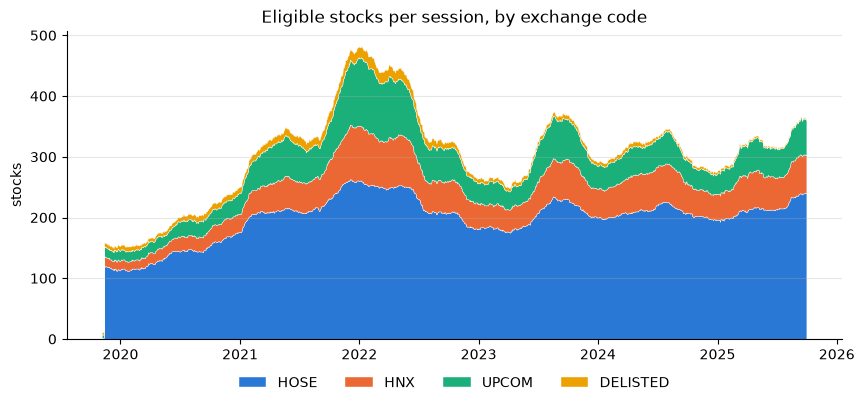

,median,min,max
date,,,
2019,154.0,11,160
2020,201.5,152,251
2021,335.0,251,482
2022,355.0,263,483
2023,300.0,249,374
2024,309.0,273,347
2025,320.0,276,366


In [2]:
by_exchange = panel.groupby(["date", "exchange"]).size().unstack(fill_value=0)
order = ["HOSE", "HNX", "UPCOM", "DELISTED"]
by_exchange = by_exchange.reindex(columns=order, fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4))
ax.stackplot(by_exchange.index, by_exchange.T.to_numpy(), labels=order,
             colors=[BLUE, ORANGE, AQUA, YELLOW], edgecolor="white", linewidth=0.3)
ax.set_title("Eligible stocks per session, by exchange code")
ax.set_ylabel("stocks")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncols=4)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
plt.show()
yearly = by_exchange.sum(axis=1).groupby(by_exchange.index.year).agg(["median", "min", "max"])
yearly

## Missingness

Share of eligible rows with a missing raw feature, and missing targets (labels not yet
matured at the end of the period, or a delisting inside the label window).

In [3]:
missing = panel[features + ["target"]].isna().mean().mul(100).round(3)
missing.to_frame("missing_%").sort_values("missing_%", ascending=False)

,missing_%
target,0.491
log_tv_20,0.018
amihud_20,0.000
vol_ratio_20,0.000
ret_5,0.000
ret_20,0.000
ret_60,0.000
ret_1,0.000
ret_120,0.000
close_to_high_252,0.000


In [4]:
late = panel.loc[panel["target"].isna()]
print("missing targets:", len(late))
print("of which in the last 6 sessions:", int((late["date"] >= panel["date"].unique()[-6]).sum()))

missing targets: 2211
of which in the last 6 sessions: 2185


## Raw feature distributions

Histograms clipped to the 1st–99th percentile for display only; the model sees per-date
ranks, which are uniform by construction.

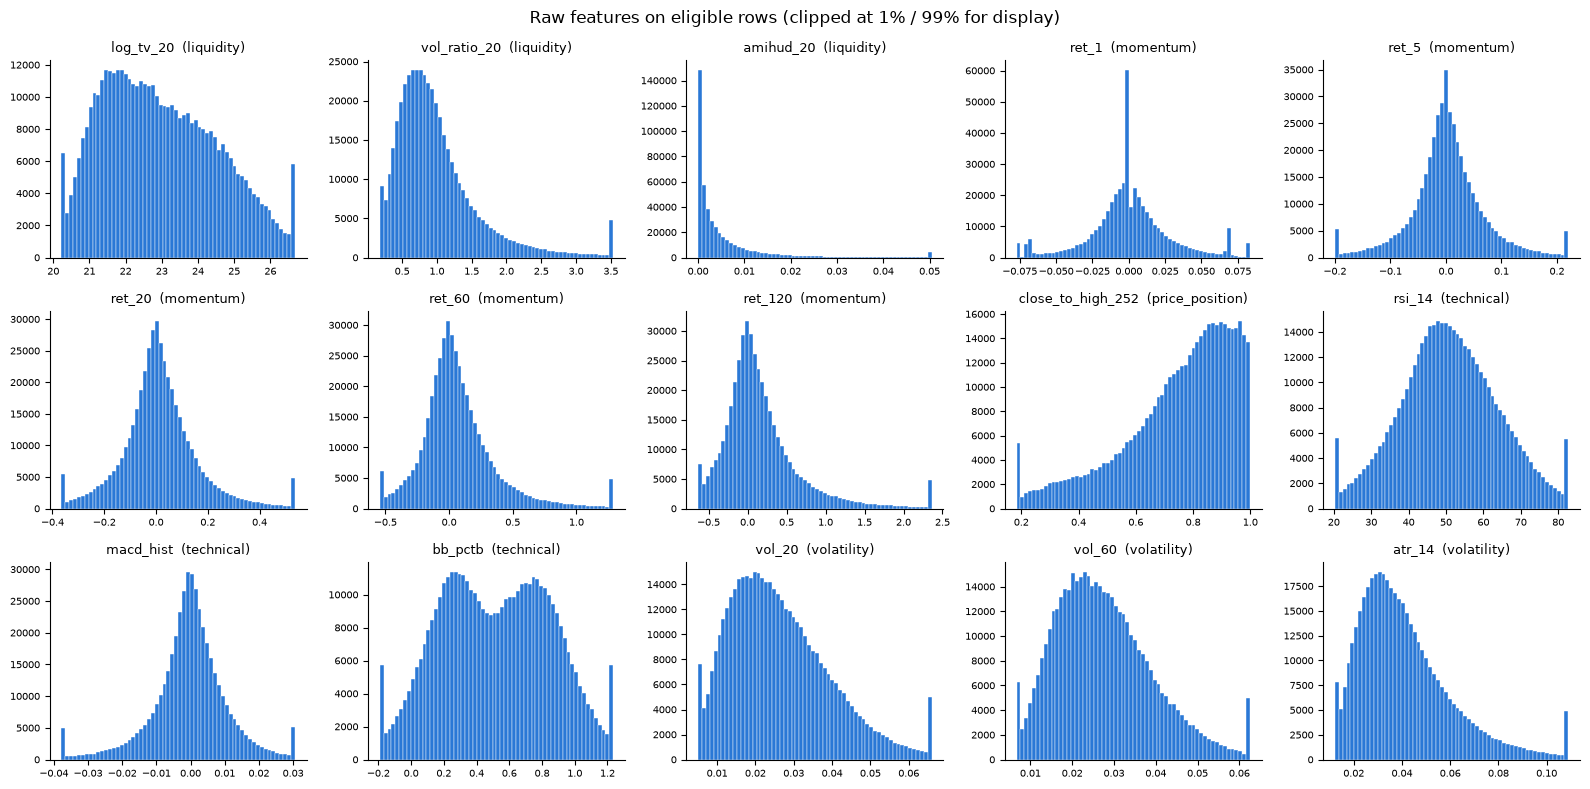

In [5]:
fig, axes = plt.subplots(3, 5, figsize=(16, 8))
for ax, name in zip(axes.flat, features):
    values = panel[name].dropna()
    low, high = values.quantile([0.01, 0.99])
    ax.hist(values.clip(low, high), bins=60, color=BLUE, edgecolor="white", linewidth=0.3)
    group = next(g for g, names in groups.items() if name in names)
    ax.set_title(f"{name}  ({group})", fontsize=9)
    ax.tick_params(labelsize=7)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Raw features on eligible rows (clipped at 1% / 99% for display)")
fig.tight_layout()
plt.show()

## Redundancy between features

Mean over dates of the per-date Spearman correlation between feature ranks (pairs of
features only; no labels).

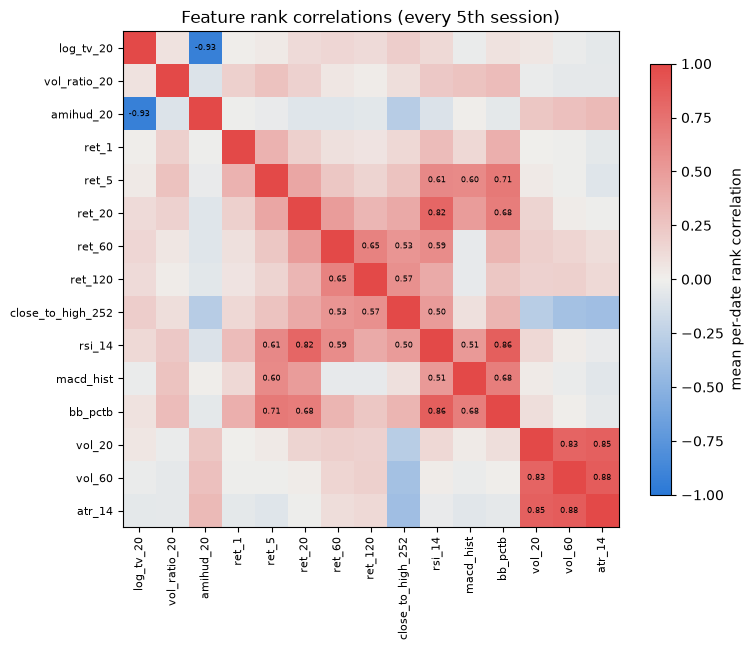

In [6]:
rank_columns = ["rank_" + name for name in features]
sample_dates = panel["date"].drop_duplicates().iloc[::5]
per_date = [
    panel.loc[panel["date"] == d, rank_columns].corr(method="pearson")  # ranks: Pearson = Spearman
    for d in sample_dates
]
corr = sum(per_date) / len(per_date)
corr.index = corr.columns = features
fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(corr.to_numpy(), cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(features)), features, rotation=90, fontsize=8)
ax.set_yticks(range(len(features)), features, fontsize=8)
for i in range(len(features)):
    for j in range(len(features)):
        if i != j and abs(corr.iat[i, j]) >= 0.5:
            ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(image, ax=ax, shrink=0.8, label="mean per-date rank correlation")
ax.set_title("Feature rank correlations (every 5th session)")
plt.show()